# LiF(e) polaron dispersion E₀(p) and effective mass

Data: `runs/dispersion/n<grid>-tau<τ>/results/<label>/merged.json` from `ironmc dispersion sweep` (`x<j>` = (j/n, 0, j/n) on Γ→X, `l<j>` = (j/n, j/n, j/n) on Γ→L). The Γ point of each grid/τ is reused from `runs/e0-fit/tau<τ>/n<grid>`. The bare band and phonons at the same points come from `runs/dispersion/band.json`:

```
cargo run --release -p rmc-ab-initio --example band_mass out> runs/dispersion/band.json
```

Symmetry and fit model: `latex/symmetry-paths/symmetry-paths.tex`. Cubic symmetry forces one scalar mass, and the legs differ first at quartic order:

$$E_0(\mathbf p) = E_0 + \frac{|\mathbf p|^2}{2m_p} + c_{4,\mathrm{leg}}\,|\mathbf p|^4 .$$

**Normalization.** FEP-DMC's $m_p/m_e$ (Table 1: 6.1 along Γ–L) divides by the *band* effective mass $m_b$, not the free-electron mass. Both are reported here: $m_p/m_e$ (free electron) and $m_p/m_b$ (band curvature at Γ, from the same Wannier ε(k) the sampler uses).

**Windows are physical, not index-based.** At fixed index $j$, $|\mathbf p| = j\cdot 2\pi/(a n)$ shrinks with $n$, so an index window conflates the grid trend with the non-parabolicity trend. All fits here use $|\mathbf p| \le p_\max$ in Å⁻¹, identical for every grid.

In [1]:
import json, re
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

A_LAT = 7.67420569894 * 0.529177210903   # celldm(1) bohr -> Angstrom (datasets/LiF/scf.in)
TPA = 2 * np.pi / A_LAT                  # 2π/a in 1/Angstrom
HB2_2ME = 3.8099821                      # ħ²/(2 m_e) in eV·Å²

band = json.load(open("../runs/dispersion/band.json"))
BAND = {(r["leg"], r["n"], r["j"]): r for r in band if r["kind"] == "grid"}
curv = {r["leg"]: r["c2_per_s2"] for r in band if r["kind"] == "curvature"}
# ε = c2·s² with |p| = TPA·2s (x) or TPA·√3·s (l)  ⇒  m_b = ħ²/2mₑ · (|p|/s)² / c2
M_B = {"x": HB2_2ME * 4 * TPA**2 / curv["x"], "l": HB2_2ME * 3 * TPA**2 / curv["l"]}
print(f"band mass m_b/mₑ: Γ→X {M_B['x']:.4f}, Γ→L {M_B['l']:.4f} (cubic ⇒ equal)")
m_b = M_B["x"]

def load(p):
    r = json.load(open(p))
    return r["e0_thermo"]["mean"], r["e0_thermo"]["stderr"], r["sign"]["mean"]

def load_sweep(sweep):
    grid, tau = map(int, re.match(r"n(\d+)-tau(\d+)", sweep.name).groups())
    e0g, e0g_err, _ = load(Path(f"../runs/e0-fit/tau{tau}/n{grid}/results/merged.json"))
    rows, missing = [], []
    for d in sorted((sweep / "results").iterdir()):
        m = d / "merged.json"
        if not m.exists():
            missing.append(d.name); continue
        leg, j = d.name[0], int(d.name[1:])
        p = TPA * (2 * j / grid if leg == "x" else np.sqrt(3) * j / grid)
        e0, err, sign = load(m)
        b = BAND.get((leg, grid, j))
        rows.append(dict(label=d.name, leg=leg, j=j, p=p, e0=e0, err=err, sign=sign,
                         de=e0 - e0g, de_err=np.hypot(err, e0g_err),
                         band=b["de"] if b else np.nan, omega=np.array(b["omega"]) if b else None))
    rows.sort(key=lambda r: (r["leg"], r["j"]))
    if missing: print(f"{sweep.name}: unfinished, skipping {missing}")
    return dict(grid=grid, tau=tau, rows=rows, e0g=e0g, e0g_err=e0g_err)

sweeps = [load_sweep(s) for s in sorted(Path("../runs/dispersion").glob("n*-tau*"),
                                        key=lambda s: tuple(map(int, re.findall(r"\d+", s.name))))]
for s in sweeps:
    print(f"n{s['grid']} τ{s['tau']}: {len(s['rows'])} points + Γ ({s['e0g']:+.5f})")

band mass m_b/mₑ: Γ→X 0.6926, Γ→L 0.6926 (cubic ⇒ equal)
n20-tau60: unfinished, skipping ['x10', 'x6', 'x7', 'x8', 'x9']
n120-tau240: unfinished, skipping ['x12']
n20 τ60: 8 points + Γ (-0.24976)
n40 τ240: 4 points + Γ (-0.32550)
n80 τ60: 8 points + Γ (-0.36198)
n80 τ240: 9 points + Γ (-0.36530)
n120 τ240: 7 points + Γ (-0.37828)


## Dispersion, thresholds, sign

Dotted and dashed lines (in each leg's colour) are one-phonon states in the $\mathbf p$ sector with the polaron at Γ and the phonon at $\mathbf q = \mathbf p$: $E_0(\Gamma) + \omega_\nu(\mathbf p)$, for the lowest (TA) branch and the LO branch. The LO line is the familiar flattening threshold. The TA line lies **below** the polaron branch at every nonzero grid momentum: this is the acoustic-emission (Landau/Cherenkov) threshold discussed in the LaTeX note. It marks where the fixed-τ estimator's τ → ∞ limit stops being the quasiparticle energy.

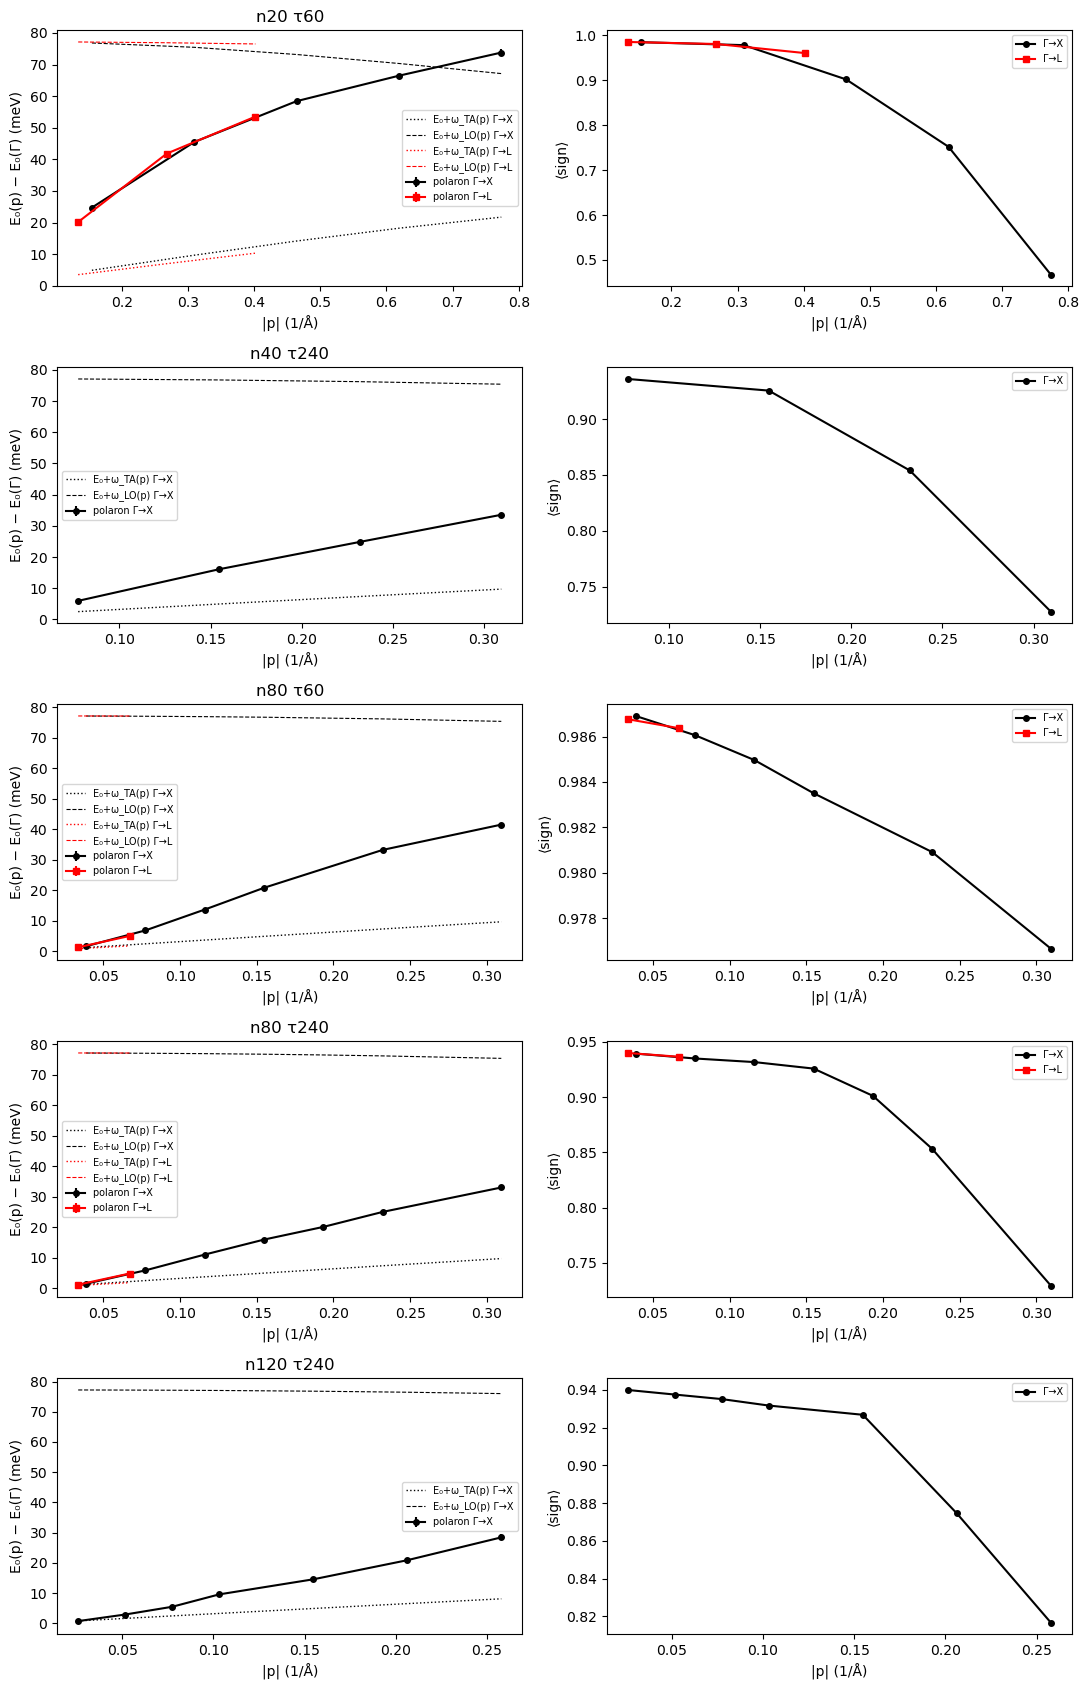

In [2]:
fig, axes = plt.subplots(len(sweeps), 2, figsize=(11, 3.4 * len(sweeps)), squeeze=False)
for (ax, ax2), s in zip(axes, sweeps):
    for leg, fmt, name in [("x", "ko-", "Γ→X"), ("l", "rs-", "Γ→L")]:
        pts = [r for r in s["rows"] if r["leg"] == leg]
        if not pts: continue
        p = np.array([r["p"] for r in pts])
        ax.errorbar(p, 1e3 * np.array([r["de"] for r in pts]), 1e3 * np.array([r["de_err"] for r in pts]), fmt=fmt, ms=4, label=f"polaron {name}")
        if pts[0]["omega"] is not None:
            ax.plot(p, 1e3 * np.array([r["omega"][0] for r in pts]), fmt[0] + ":", lw=1, label=f"E₀+ω_TA(p) {name}")
            ax.plot(p, 1e3 * np.array([r["omega"][-1] for r in pts]), fmt[0] + "--", lw=0.8, label=f"E₀+ω_LO(p) {name}")
        ax2.plot(p, [r["sign"] for r in pts], fmt, ms=4, label=name)
    ax.set_title(f"n{s['grid']} τ{s['tau']}"); ax.set_xlabel("|p| (1/Å)"); ax.set_ylabel("E₀(p) − E₀(Γ) (meV)"); ax.legend(fontsize=7)
    ax2.set_xlabel("|p| (1/Å)"); ax2.set_ylabel("⟨sign⟩"); ax2.legend(fontsize=7)
plt.tight_layout(); plt.savefig("dispersion.png", dpi=150); plt.show()

## Linearized: ΔE/p² vs p²

$\Delta E/p^2 = 1/(2m_p) + c_4 p^2$. Legs share the intercept, curvature marks where $p^6$ terms enter, and grids that agree at the same $|\mathbf p|$ show that the dispersion is grid-converged there. The dashed curves are the bare band divided by the same $p^2$, scaled by 1/5 to fit the axis.

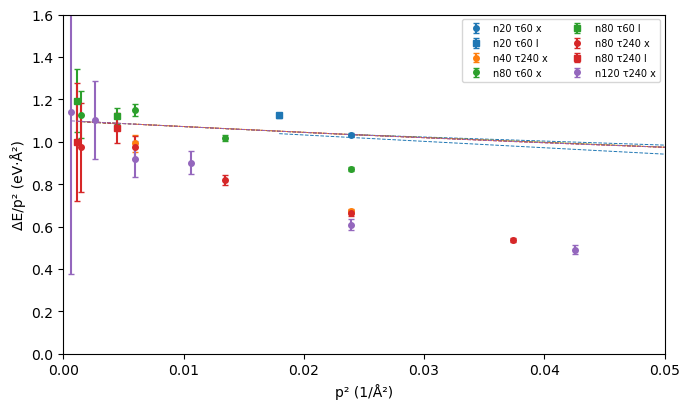

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for k, s in enumerate(sweeps):
    for leg, mk in [("x", "o"), ("l", "s")]:
        pts = [r for r in s["rows"] if r["leg"] == leg]
        if not pts: continue
        p = np.array([r["p"] for r in pts])
        y = np.array([r["de"] for r in pts]) / p**2; e = np.array([r["de_err"] for r in pts]) / p**2
        ax.errorbar(p**2, y, e, fmt=mk, color=f"C{k}", ms=4, capsize=2, label=f"n{s['grid']} τ{s['tau']} {leg}")
        ax.plot(p**2, np.array([r["band"] for r in pts]) / p**2 / 5, "--", color=f"C{k}", lw=0.7)
ax.set_xlim(0, 0.05); ax.set_ylim(0, 1.6)
ax.set_xlabel("p² (1/Å²)"); ax.set_ylabel("ΔE/p² (eV·Å²)"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig("mass-linearized.png", dpi=150); plt.show()

## Joint fit per grid, physical window scan

Weighted linear least squares: shared $1/(2m_p)$, a per-leg quartic, and $E_0(\Gamma)$ fixed to the banked value. Errors on $\Delta E$ include the Γ-point error. The Γ error is common to every point, so it is slightly over-counted as independent here; this is conservative. The bare band is fitted with the identical points and model, so "same-window $m_p/m_b$" cancels most of the band non-parabolicity. The quoted number is $m_p/m_b$ from the curvature at Γ.

In [4]:
def joint_fit(s, pmax, quartic=True):
    pts = [r for r in s["rows"] if r["p"] <= pmax + 1e-9]
    if not pts: return None
    p = np.array([r["p"] for r in pts]); y = np.array([r["de"] for r in pts]); w = 1 / np.array([r["de_err"] for r in pts])
    b = np.array([r["band"] for r in pts])
    legs = sorted({r["leg"] for r in pts})
    M = np.column_stack([p**2] + ([np.array([r["leg"] == l for r in pts]) * p**4 for l in legs] if quartic else []))
    if len(p) <= M.shape[1]: return None
    Mw = M * w[:, None]
    c, *_ = np.linalg.lstsq(Mw, y * w, rcond=None)
    cov = np.linalg.inv(Mw.T @ Mw)
    chi2 = np.sum((M @ c - y)**2 * w**2) / (len(p) - M.shape[1])
    cb, *_ = np.linalg.lstsq(M, b, rcond=None)
    mp = HB2_2ME / c[0]
    err = mp * np.sqrt(cov[0, 0]) / c[0] * max(1.0, np.sqrt(chi2))
    return dict(mstar=mp, err=err, ratio=mp / m_b, ratio_err=err / m_b,
                ratio_window=mp / (HB2_2ME / cb[0]), chi2red=chi2, npts=len(p))

PMAXES = [0.08, 0.12, 0.16, 0.21, 0.26]
for s in sweeps:
    print(f"-- n{s['grid']} τ{s['tau']}")
    for pmax in PMAXES:
        for quartic in (False, True):
            f = joint_fit(s, pmax, quartic)
            if f:
                print(f"   p≤{pmax:.2f} {'p²+p⁴' if quartic else 'p²   '}: {f['npts']} pts  m_p/mₑ = {f['mstar']:.2f} ± {f['err']:.2f}"
                      f"  m_p/m_b = {f['ratio']:.2f} ± {f['ratio_err']:.2f}  (same-window {f['ratio_window']:.2f})  χ²/dof = {f['chi2red']:.1f}")

-- n20 τ60
   p≤0.16 p²   : 2 pts  m_p/mₑ = 3.56 ± 0.15  m_p/m_b = 5.14 ± 0.21  (same-window 4.84)  χ²/dof = 45.6
   p≤0.21 p²   : 2 pts  m_p/mₑ = 3.56 ± 0.15  m_p/m_b = 5.14 ± 0.21  (same-window 4.84)  χ²/dof = 45.6
   p≤0.26 p²   : 2 pts  m_p/mₑ = 3.56 ± 0.15  m_p/m_b = 5.14 ± 0.21  (same-window 4.84)  χ²/dof = 45.6
-- n40 τ240
   p≤0.16 p²   : 2 pts  m_p/mₑ = 5.50 ± 0.63  m_p/m_b = 7.94 ± 0.90  (same-window 7.48)  χ²/dof = 60.2
   p≤0.21 p²   : 2 pts  m_p/mₑ = 5.50 ± 0.63  m_p/m_b = 7.94 ± 0.90  (same-window 7.48)  χ²/dof = 60.2
   p≤0.26 p²   : 3 pts  m_p/mₑ = 7.50 ± 1.03  m_p/m_b = 10.84 ± 1.49  (same-window 9.63)  χ²/dof = 237.3
   p≤0.26 p²+p⁴: 3 pts  m_p/mₑ = 4.36 ± 0.40  m_p/m_b = 6.30 ± 0.57  (same-window 6.24)  χ²/dof = 20.0
-- n80 τ60
   p≤0.08 p²   : 4 pts  m_p/mₑ = 3.34 ± 0.06  m_p/m_b = 4.83 ± 0.09  (same-window 4.76)  χ²/dof = 0.2
   p≤0.08 p²+p⁴: 4 pts  m_p/mₑ = 3.30 ± 0.34  m_p/m_b = 4.76 ± 0.49  (same-window 4.76)  χ²/dof = 0.2
   p≤0.12 p²   : 5 pts  m_p/mₑ = 3.63 ±

## Quoted mass and the grid ladder

A pure parabola is inconsistent with the data beyond $|\mathbf p|\approx0.1$ Å⁻¹: $\chi^2$ grows and $m_p$ drifts upward, because the dispersion bends toward the phonon thresholds. That drift is exactly how a "parabolic fit" can report anything from ≈5 to ≈9 $m_b$, depending on its range. The quoted value is the $p\to0$ curvature from the $p^2+p^4$ fit at $p_\max$ = `P_QUOTE`. Its window systematic is the spread over the neighbouring windows. The grid ladder is taken at that fixed physical window.

n20 τ60: not enough points ≤ 0.16 Å⁻¹
n40 τ240: not enough points ≤ 0.16 Å⁻¹
n80 τ60: m_p/m_b = 4.52 ± 0.09 (stat) ± 0.06 (window)   m_p/mₑ = 3.13
n80 τ240: m_p/m_b = 5.31 ± 0.23 (stat) ± 0.42 (window)   m_p/mₑ = 3.68
n120 τ240: m_p/m_b = 5.01 ± 0.32 (stat) ± 1.01 (window)   m_p/mₑ = 3.47
τ240 grids [80, 120]: weighted mean m_p/m_b = 5.26 ± 0.44, χ²/dof (constant in n) = 0.07


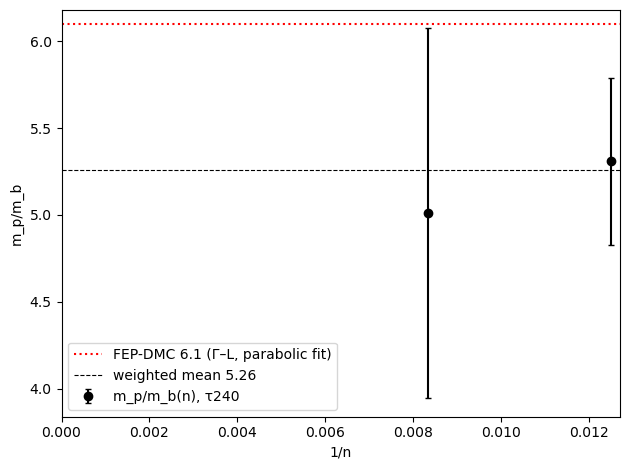

In [5]:
P_QUOTE = 0.16          # Å⁻¹; set from the scan above (χ²/dof ≈ 1 and stable against ±1 window)
ladder = []
for s in sweeps:
    f = joint_fit(s, P_QUOTE, True)
    nb = [joint_fit(s, pm, True) for pm in PMAXES if abs(pm - P_QUOTE) < 0.06 and pm != P_QUOTE]
    nb = [x for x in nb if x]
    if f is None:
        print(f"n{s['grid']} τ{s['tau']}: not enough points ≤ {P_QUOTE} Å⁻¹"); continue
    wsys = max((abs(x["ratio"] - f["ratio"]) for x in nb), default=np.nan)
    ladder.append(dict(grid=s["grid"], tau=s["tau"], wsys=wsys, **f))
    print(f"n{s['grid']} τ{s['tau']}: m_p/m_b = {f['ratio']:.2f} ± {f['ratio_err']:.2f} (stat) ± {wsys:.2f} (window)   m_p/mₑ = {f['mstar']:.2f}")

prod = [l for l in ladder if l["tau"] == 240]
if len(prod) >= 2:
    u = 1 / np.array([l["grid"] for l in prod]); r = np.array([l["ratio"] for l in prod])
    e = np.hypot([l["ratio_err"] for l in prod], np.nan_to_num([l["wsys"] for l in prod]))
    wmean = np.sum(r / e**2) / np.sum(1 / e**2)
    chi2 = np.sum(((r - wmean) / e)**2) / max(len(r) - 1, 1)
    print(f"τ240 grids {[l['grid'] for l in prod]}: weighted mean m_p/m_b = {wmean:.2f} ± {1/np.sqrt(np.sum(1/e**2)):.2f}, χ²/dof (constant in n) = {chi2:.2f}")
    plt.errorbar(u, r, e, fmt="ko", capsize=2, label="m_p/m_b(n), τ240")
    plt.axhline(6.1, color="r", ls=":", label="FEP-DMC 6.1 (Γ–L, parabolic fit)")
    plt.axhline(wmean, color="k", ls="--", lw=0.8, label=f"weighted mean {wmean:.2f}")
    plt.xlabel("1/n"); plt.ylabel("m_p/m_b"); plt.xlim(left=0); plt.legend(); plt.tight_layout(); plt.savefig("mass-ladder.png", dpi=150); plt.show()

## Landau-threshold diagnostic: τ60 vs τ240 at the same (n, p)

If $E_0(\mathbf p,\tau)$ measures the quasiparticle, then $E_0(\mathbf p,\tau240)-E_0(\mathbf p,\tau60)$ equals the Γ shift at that grid (about −2.8 meV for $n\ge40$) at every $\mathbf p$. If polaron + acoustic-phonon states below the quasiparticle contaminate it, the difference grows more negative with $|\mathbf p|$. This cell needs a τ60 sweep at a grid that also has a τ240 sweep.

In [6]:
by = {(s["grid"], s["tau"]): s for s in sweeps}
pairs = [(g, by[(g, 60)], by[(g, 240)]) for g in sorted({g for g, _ in by}) if (g, 60) in by and (g, 240) in by]
if not pairs:
    print("no grid has both τ60 and τ240 sweeps yet — e.g. `ironmc dispersion sweep 80 --tau 60 --x-js [1 2 3 4 6 8] --l-js [1 2]`")
for g, a, b in pairs:
    ra = {r["label"]: r for r in a["rows"]}
    shift_g = b["e0g"] - a["e0g"]
    print(f"n{g}: Γ shift τ240−τ60 = {1e3*shift_g:+.2f} meV")
    for r in b["rows"]:
        if r["label"] in ra:
            d = r["e0"] - ra[r["label"]]["e0"]; de = np.hypot(r["err"], ra[r["label"]]["err"])
            print(f"   {r['label']:>4} |p| = {r['p']:.3f}: τ240−τ60 = {1e3*d:+.2f} ± {1e3*de:.2f} meV  (excess over Γ: {1e3*(d-shift_g):+.2f})")

n80: Γ shift τ240−τ60 = -3.32 meV
     l1 |p| = 0.033: τ240−τ60 = -3.53 ± 0.18 meV  (excess over Γ: -0.22)
     l2 |p| = 0.067: τ240−τ60 = -3.57 ± 0.19 meV  (excess over Γ: -0.25)
     x1 |p| = 0.039: τ240−τ60 = -3.54 ± 0.18 meV  (excess over Γ: -0.23)
     x2 |p| = 0.077: τ240−τ60 = -4.36 ± 0.19 meV  (excess over Γ: -1.05)
     x3 |p| = 0.116: τ240−τ60 = -6.01 ± 0.21 meV  (excess over Γ: -2.70)
     x4 |p| = 0.155: τ240−τ60 = -8.23 ± 0.23 meV  (excess over Γ: -4.92)
     x6 |p| = 0.232: τ240−τ60 = -11.57 ± 0.29 meV  (excess over Γ: -8.26)
     x8 |p| = 0.309: τ240−τ60 = -11.85 ± 0.38 meV  (excess over Γ: -8.53)
